# 2.29 · Choosing hyperparameters and comparing models

**Before this:** [2.08](2-08_bayesian_linear_map.ipynb) (Bayesian linear inversion), [2.09](2-09_regularisation_smoothing.ipynb) (regularisation), [2.28](2-28_kl_divergence.ipynb) (KL divergence, for AIC)  
**You will be able to:** choose a smoothing weight with the L-curve, GCV, ABIC or a hierarchical posterior and say
what each one measures; compare models with AIC, BIC and the evidence, and know why the evidence moves with prior
width; avoid ranking a weighting knob with its own weighted misfit; report the fit per data set  
**Optional sections:** 3 (wrong prior family)

Every inversion has knobs that the physics does not set: how strongly to smooth, how much to trust each data set,
how many parameters the model should have. Knobs of the prior or of the noise model, rather than of the Earth, are
called **hyperparameters** (reminder: 2.12). This notebook shows how the usual tools set them, what each tool
actually measures, and two ways they mislead. All examples are synthetic, so the right answer is known.

**Words this notebook defines:** hyperparameter, L-curve, generalised cross-validation (GCV), marginal likelihood
(evidence), ABIC, hierarchical estimation, AIC, BIC, Occam penalty, prior-width sensitivity, circular metric,
WRMS, χ² per data set.

**Problems in this notebook**

| problem | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| antiplane fault slip with smoothing (sections 1-3) | 30 patches + 1 hyperparameter λ | 24 stations, σ = 3 mm | screw-dislocation Green's functions $\mathbf d = \mathbf G\mathbf m$ | linear in slip |
| postseismic GPS time series (sections 4-5) | 2 to 7 amplitudes (time constants fixed) | 730 daily values, σ = 2 mm | sums of log, exponential and polynomial terms | linear in the amplitudes |
| two data sets with a balancing exponent β (section 6) | 2 + β | 200 + 10 | straight-line combinations of the unknowns | linear |

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import matplotlib.pyplot as plt
import bayeskit as bk
from bayeskit import problems as P, samplers as SM, diagnostics as D, plotting as BP, style as S
from scipy.signal import lfilter
from collections import Counter

C_LC, C_GCV, C_ABIC, C_ERR = S.ORANGE, S.AQUA, S.BLUE, S.INK      # one colour per criterion
C_HIER = S.VIOLET

N = 30
z_edges = np.linspace(0.0, 30.0, N + 1)
zc = 0.5 * (z_edges[1:] + z_edges[:-1])
xs = np.array([1, 2, 3, 4, 6, 9, 13, 18, 25, 35, 50, 70.0])
xs = np.sort(np.r_[-xs, xs])
sig = 3.0


def patch_disp(x, z1, z2):
    return (np.arctan(z2 / x) - np.arctan(z1 / x)) / np.pi


G = 1000.0 * np.array([[patch_disp(x, z_edges[j], z_edges[j + 1]) for j in range(N)] for x in xs])
m_true = 2.0 * np.exp(-0.5 * ((zc - 12.0) / 4.0) ** 2)               # the slip of notebook 2.33: 2 m at 12 km
Gt = G / sig                                                        # data whitened by the noise: C_d = I
I_N = np.eye(N)
D_bc = np.vstack([np.diff(I_N, n=2, axis=0), I_N[-1:]])             # second difference + zero slip at 30 km
D_free = np.diff(I_N, n=2, axis=0)                                  # second difference, free edges
lams = np.logspace(-4, 4, 161)


def operator_terms(Dm):
    DD = Dm.T @ Dm
    ev = np.linalg.eigvalsh(DD)
    keep = ev > 1e-10 * ev.max()
    return DD, int(keep.sum()), float(np.sum(np.log(ev[keep])))


def scan(d, Dm):
    """For every lambda: the solution, its fit, roughness, ABIC, GCV and (synthetic only) its error."""
    DD, r, ldp = operator_terms(Dm)
    dt = d / sig
    out = {k: [] for k in ["m", "chi2", "rough", "logdetA", "abic", "gcv", "err"]}
    for lam in lams:
        A = Gt.T @ Gt + lam * DD
        m = np.linalg.solve(A, Gt.T @ dt)
        res = dt - Gt @ m
        chi2, rough = res @ res, m @ DD @ m
        ldA = np.linalg.slogdet(A)[1]
        H = Gt @ np.linalg.solve(A, Gt.T)
        out["m"].append(m); out["chi2"].append(chi2); out["rough"].append(rough); out["logdetA"].append(ldA)
        out["abic"].append(chi2 + lam * rough + ldA - r * np.log(lam) - ldp + 2)        # + lambda-free constants
        out["gcv"].append(len(xs) * res @ res / (len(xs) - np.trace(H)) ** 2)
        out["err"].append(np.sqrt(np.mean((m - m_true) ** 2)))
    out = {k: np.array(v) for k, v in out.items()}
    out["r"] = r
    return out


def lcurve_corner(o):
    """Index of maximum curvature of (log residual norm, log roughness norm) as a function of log lambda."""
    x, y, t = 0.5 * np.log(o["chi2"]), 0.5 * np.log(o["rough"]), np.log(lams)
    dx, dy = np.gradient(x, t), np.gradient(y, t)
    ddx, ddy = np.gradient(dx, t), np.gradient(dy, t)
    kappa = (dx * ddy - dy * ddx) / (dx ** 2 + dy ** 2) ** 1.5
    return int(np.argmax(kappa)), kappa


def lambda_posterior(o):
    """p(lambda | d) on the grid, with a log-uniform prior on lambda (flat in log lambda)."""
    logp = -0.5 * (o["abic"] - 2)
    w = np.exp(logp - logp.max())
    return w / np.trapezoid(w, np.log10(lams))


def picks(o):
    corner, _ = lcurve_corner(o)
    post = lambda_posterior(o)
    cdf = np.cumsum(post) * (np.log10(lams[1]) - np.log10(lams[0]))
    return {"L-curve": corner, "GCV": int(np.argmin(o["gcv"])), "ABIC": int(np.argmin(o["abic"])),
            "hierarchical (posterior median)": int(np.argmin(np.abs(cdf / cdf[-1] - 0.5))),
            "error-optimal (synthetic only)": int(np.argmin(o["err"]))}


PCOL = {"L-curve": C_LC, "GCV": C_GCV, "ABIC": C_ABIC, "hierarchical (posterior median)": C_HIER,
        "error-optimal (synthetic only)": C_ERR}

## 1. The knob: the smoothing weight λ

**In plain words.** A slip inversion with more patches than the data can resolve needs a rule for the parts the
data do not see. Smoothing is such a rule: among all slip models that fit, prefer smooth ones. The weight λ says
how much smoothness may cost in fit. Too small, and noise is fitted with wiggles; too large, and the slip is
flattened into whatever the smoothing considers simplest.

**Precisely.** With whitened data ($\mathbf C_d = \mathbf I$ after dividing by σ; reminder: whitening, 2.06),

$$\mathbf m_\lambda = \arg\min_{\mathbf m}\ \lVert\mathbf d - \mathbf G\mathbf m\rVert^2 + \lambda\,\lVert\mathbf D\mathbf m\rVert^2
  = (\mathbf G^\top\mathbf G + \lambda\,\mathbf D^\top\mathbf D)^{-1}\mathbf G^\top\mathbf d ,$$

the MAP of a Gaussian prior with precision $\lambda\mathbf D^\top\mathbf D$ (2.08, 2.09). Here $\mathbf D$ is the second difference
down dip plus one row that asks for zero slip at the bottom edge (30 km). $\mathbf D^\top\mathbf D$ then has rank
$r = N_m - 1$: one direction (a linear trend that vanishes at 30 km) is not penalised at all.

saved figures/2-29_knob.png


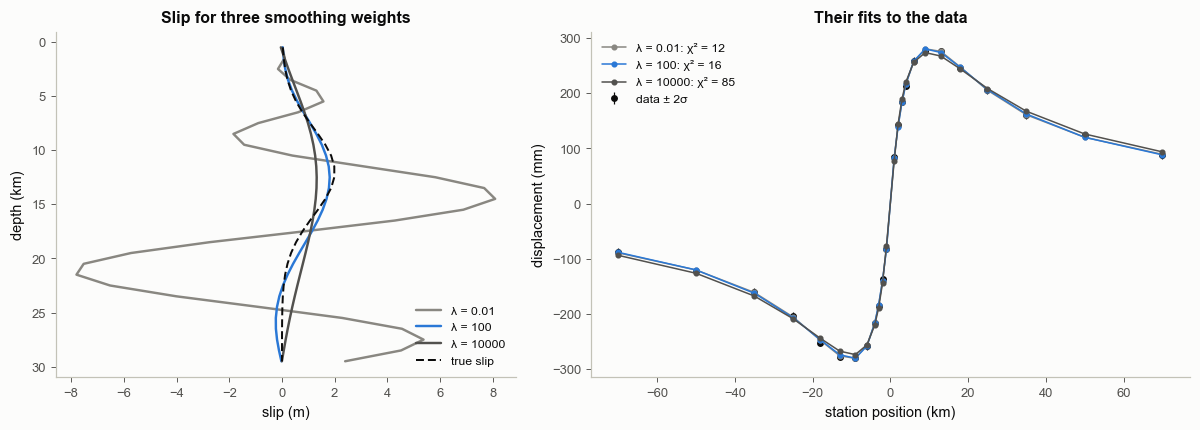

expected chi^2 of a fit at the noise level: about N_d = 24


In [2]:
d0 = G @ m_true + sig * np.random.default_rng(42).standard_normal(xs.size)
o0 = scan(d0, D_bc)
show = [1e-2, 1e2, 1e4]
fig, axs = plt.subplots(1, 2, figsize=(11, 4.0), gridspec_kw=dict(width_ratios=[1, 1.3]))
for lam, shade in zip(show, [S.MUTED, S.BLUE, S.INK2]):
    i = int(np.argmin(np.abs(lams - lam)))
    axs[0].plot(o0["m"][i], zc, color=shade, lw=1.6, label=f"λ = {lam:g}")
    axs[1].plot(xs, G @ o0["m"][i], "o-", ms=3, lw=1, color=shade, label=f"λ = {lam:g}: χ² = {o0['chi2'][i]:.0f}")
axs[0].plot(m_true, zc, color=S.INK, lw=1.3, ls=(0, (4, 2)), label="true slip")
axs[0].invert_yaxis(); axs[0].set_xlabel("slip (m)"); axs[0].set_ylabel("depth (km)")
axs[0].set_title("Slip for three smoothing weights"); axs[0].legend(fontsize=8, loc="lower right")
axs[1].errorbar(xs, d0, yerr=2 * sig, fmt="o", color=S.INK, ms=3.5, lw=0.8, capsize=0, label="data ± 2σ", zorder=0)
axs[1].set_xlabel("station position (km)"); axs[1].set_ylabel("displacement (mm)")
axs[1].set_title("Their fits to the data"); axs[1].legend(fontsize=8, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "2-29_knob")
plt.show()
print("expected chi^2 of a fit at the noise level: about N_d =", xs.size)

**How to read it.** Small λ (grey) follows the data closely and lets the slip wiggle; large λ (dark) gives a
nearly straight slip profile that misses the data near the fault (its χ² far above $N_d$). Somewhere between lies
a good compromise. The rest of this section is about finding it without knowing the true slip.

## 2. Four ways to choose λ, and the answer only a synthetic test knows

**In plain words.**
* **L-curve**: plot misfit against roughness for many λ; the curve has a corner where a little extra roughness
  no longer buys much fit. Take the corner.
* **GCV**: leave each datum out in turn, predict it from the rest, and pick the λ with the best average
  prediction (computed in one formula, without refitting).
* **ABIC**: ask how probable the observed data were under each λ *before* seeing them, averaging over all slip
  models the prior allows. A too-rough prior spreads its probability over wild data; a too-smooth prior cannot
  produce the observed data at all. Take the λ that made the data most probable.
* **Hierarchical**: treat λ as one more unknown with its own prior and report its posterior (what Fukuda & Johnson
  2008 do by sampling); the slip uncertainty then includes the uncertainty in λ.

**Precisely.**
* L-curve corner: maximum curvature of $(\log\lVert\mathbf d - \mathbf G\mathbf m_\lambda\rVert,\ \log\lVert\mathbf D\mathbf m_\lambda\rVert)$ (Hansen 1992).
* GCV: $V(\lambda) = N_d\,\lVert(\mathbf I - \mathbf H_\lambda)\mathbf d\rVert^2/\big[\operatorname{tr}(\mathbf I - \mathbf H_\lambda)\big]^2$ with
  $\mathbf H_\lambda = \mathbf G(\mathbf G^\top\mathbf G + \lambda\mathbf D^\top\mathbf D)^{-1}\mathbf G^\top$ (Golub, Heath & Wahba 1979).
  $\mathbf H_\lambda$ is the "hat" matrix that turns the data into the fitted predictions, $\hat{\mathbf d} = \mathbf H_\lambda\mathbf d$;
  its trace (the sum of the diagonal) is the effective number of parameters the fit used, so the denominator is the
  number of data left over to estimate the noise.
* ABIC (Akaike 1980; Yabuki & Matsu'ura 1992): $\mathrm{ABIC}(\lambda) = -2\ln p(\mathbf d\mid\lambda) + 2\times(\text{number of hyperparameters})$,
  with the marginal likelihood of the linear-Gaussian model in closed form (reminder: the marginal likelihood
  $p(\mathbf d\mid\lambda)$ is the probability of the data with the slip averaged out over its prior, 2.12; $\lvert\cdot\rvert$
  is the determinant and $\ln\lvert\cdot\rvert$ the log-determinant, 2.06),

$$-2\ln p(\mathbf d\mid\lambda) = \underbrace{\lVert\mathbf d - \mathbf G\mathbf m_\lambda\rVert^2 + \lambda\lVert\mathbf D\mathbf m_\lambda\rVert^2}_{\text{fit + roughness}}
  + \underbrace{\ln\lvert\mathbf G^\top\mathbf G + \lambda\mathbf D^\top\mathbf D\rvert - r\ln\lambda}_{\text{complexity}} - \ln\lvert\mathbf D^\top\mathbf D\rvert_+ + \text{const}.$$

  The terms with $r$ and $\lvert\mathbf D^\top\mathbf D\rvert_+$ come from the prior's **normalising constant**: the factor that
  makes a density integrate to one. For the smoothing prior $p(\mathbf m\mid\lambda) \propto \exp(-\tfrac\lambda2\lVert\mathbf D\mathbf m\rVert^2)$ it
  is $(\lambda^r\lvert\mathbf D^\top\mathbf D\rvert_+)^{1/2}(2\pi)^{-r/2}$. It depends on λ, so it cannot be dropped when λ is
  being chosen: a stiffer prior is more concentrated, and its density is correspondingly higher. The smoothing prior
  says nothing about the one unpenalised direction, so that direction gets a flat prior; the normalising constant then
  uses the rank $r$ (2.06) and the product of the non-zero eigenvalues $\lvert\mathbf D^\top\mathbf D\rvert_+$ (the
  "rank-deficient" form used in geodetic ABIC). The next cell checks it against a proper prior
  $\lambda\mathbf D^\top\mathbf D + \varepsilon\mathbf I$ with a tiny fixed ε.
* Hierarchical: $p(\lambda\mid\mathbf d)\propto p(\mathbf d\mid\lambda)\,p(\lambda)$ with a prior flat in $\log\lambda$ (every decade
  of λ equally likely; 2.11 explains why "flat" depends on the variable); with one hyperparameter a grid gives it
  exactly. 2.30 develops the hierarchical approach.

In [3]:
DD, r_bc, ldp = operator_terms(D_bc)
eps = 1e-8
gap, proper_curve = [], []
for lam in lams:
    Pp = lam * DD + eps * I_N
    Ae = Gt.T @ Gt + Pp
    me = np.linalg.solve(Ae, Gt.T @ (d0 / sig))
    re = d0 / sig - Gt @ me
    proper = re @ re + me @ Pp @ me + np.linalg.slogdet(Ae)[1] - np.linalg.slogdet(Pp)[1]
    gap.append((o0["abic"][list(lams).index(lam)] - 2) - proper)
    proper_curve.append(proper)
gap = np.array(gap)
print(f"rank of D^T D: {r_bc} of {N}")
print(f"rank-deficient ABIC minus proper-prior version (eps = {eps:g}): mean {gap.mean():.3f}, "
      f"spread over all lambda {gap.max() - gap.min():.2e}  (theory: the constant (N_m - r) ln eps = {(N - r_bc) * np.log(eps):.3f})")
print(f"lambda chosen by the rank-deficient form: {lams[np.argmin(o0['abic'])]:.4g}; by the proper-prior form: {lams[np.argmin(proper_curve)]:.4g}")
print("\nworked example: the two halves of -2 ln p(d | lambda) for three lambdas")
print(f"{'lambda':>8s} {'fit + roughness':>16s} {'complexity':>11s} {'sum':>9s}")
for lam in [1e0, 1e2, 1e4]:
    i = int(np.argmin(np.abs(lams - lam)))
    fr = o0["chi2"][i] + lams[i] * o0["rough"][i]
    cx = o0["logdetA"][i] - r_bc * np.log(lams[i])
    print(f"{lams[i]:8.0e} {fr:16.2f} {cx:11.2f} {fr + cx:9.2f}")

rank of D^T D: 29 of 30
rank-deficient ABIC minus proper-prior version (eps = 1e-08): mean -18.401, spread over all lambda 3.18e-01  (theory: the constant (N_m - r) ln eps = -18.421)
lambda chosen by the rank-deficient form: 70.79; by the proper-prior form: 70.79

worked example: the two halves of -2 ln p(d | lambda) for three lambdas
  lambda  fit + roughness  complexity       sum
   1e+00            14.68       60.58     75.26
   1e+02            20.31       41.27     61.58
   1e+04           139.29       28.49    167.78


**Worked example (printed above).** Raising λ makes the fit-plus-roughness half grow (the slip can no longer
follow the data) while the complexity half shrinks (a stiffer prior allows fewer different data sets, so the
observed ones become relatively more probable). ABIC sits where their sum is smallest. The check above it shows the
rank-deficient form differs from a proper prior by almost exactly the constant $(N_m - r)\ln\varepsilon$, and both forms
pick the same λ (printed).

saved figures/2-29_lambda_axis.png


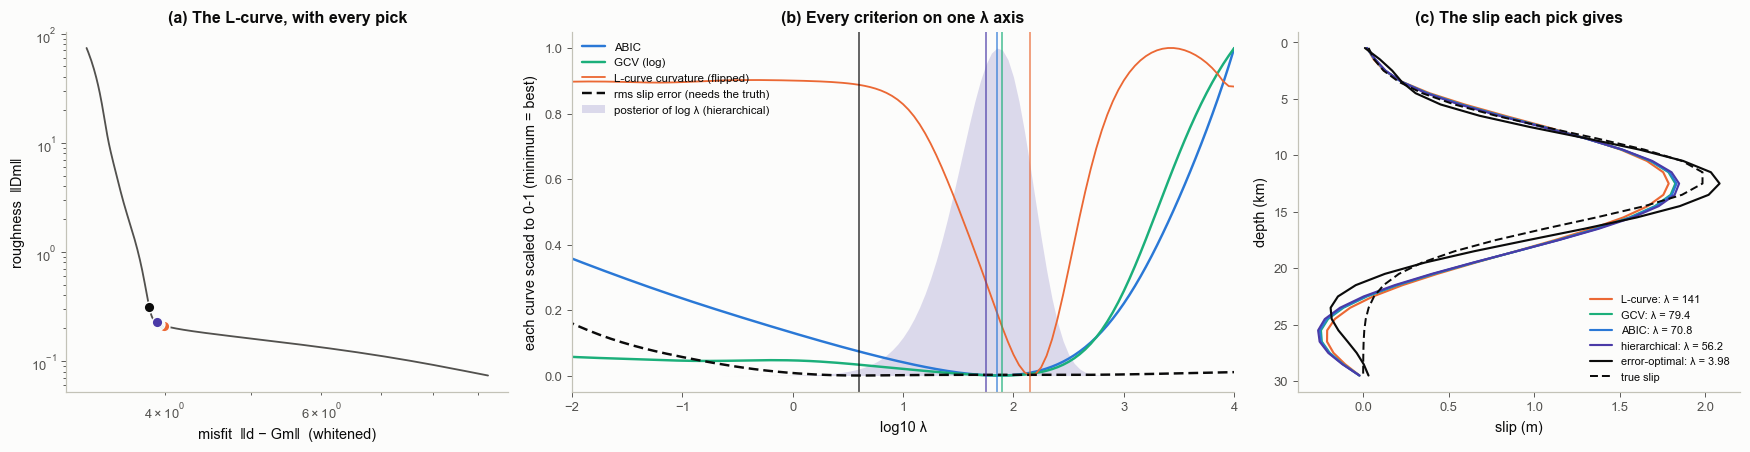

L-curve                            lambda =       141   rms slip error 0.170 m
GCV                                lambda =      79.4   rms slip error 0.175 m
ABIC                               lambda =      70.8   rms slip error 0.176 m
hierarchical (posterior median)    lambda =      56.2   rms slip error 0.177 m
error-optimal (synthetic only)     lambda =      3.98   rms slip error 0.126 m


In [4]:
pk0 = picks(o0)
corner, kappa = lcurve_corner(o0)
post0 = lambda_posterior(o0)
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw=dict(width_ratios=[1, 1.5, 1]))
ax = axs[0]
ax.loglog(np.sqrt(o0["chi2"]), np.sqrt(o0["rough"]), color=S.INK2, lw=1.2)
for name, i in pk0.items():
    ax.plot(np.sqrt(o0["chi2"][i]), np.sqrt(o0["rough"][i]), "o", color=PCOL[name], ms=7, mec=S.SURFACE)
ax.set_xlabel("misfit  ‖d − Gm‖  (whitened)"); ax.set_ylabel("roughness  ‖Dm‖")
ax.set_title("(a) The L-curve, with every pick")
ax = axs[1]
lx = np.log10(lams)
norm = lambda v: (v - v.min()) / (v.max() - v.min())
ax.plot(lx, norm(o0["abic"]), color=C_ABIC, lw=1.6, label="ABIC")
ax.plot(lx, norm(np.log(o0["gcv"])), color=C_GCV, lw=1.6, label="GCV (log)")
ax.plot(lx, norm(-kappa), color=C_LC, lw=1.2, label="L-curve curvature (flipped)")
ax.plot(lx, norm(o0["err"]), color=C_ERR, lw=1.6, ls=(0, (4, 2)), label="rms slip error (needs the truth)")
ax.fill_between(lx, 0, post0 / post0.max(), color=C_HIER, alpha=0.18, lw=0, label="posterior of log λ (hierarchical)")
for name, i in pk0.items():
    ax.axvline(lx[i], color=PCOL[name], lw=1, alpha=0.8)
ax.set_xlabel("log10 λ"); ax.set_ylabel("each curve scaled to 0-1 (minimum = best)")
ax.set_title("(b) Every criterion on one λ axis"); ax.legend(fontsize=7.5, loc="upper left")
ax.set_xlim(-2, 4)
ax = axs[2]
for name, i in pk0.items():
    ax.plot(o0["m"][i], zc, color=PCOL[name], lw=1.4, label=f"{name.split(' (')[0]}: λ = {lams[i]:.3g}")
ax.plot(m_true, zc, color=S.INK, lw=1.3, ls=(0, (4, 2)), label="true slip")
ax.invert_yaxis(); ax.set_xlabel("slip (m)"); ax.set_ylabel("depth (km)")
ax.set_title("(c) The slip each pick gives"); ax.legend(fontsize=7.2, loc="lower right")
fig.tight_layout()
bk.savefig(fig, "2-29_lambda_axis")
plt.show()
for name, i in pk0.items():
    print(f"{name:34s} lambda = {lams[i]:9.3g}   rms slip error {o0['err'][i]:.3f} m")

**How to read it.** (a) The L-curve, each dot one method's pick. (b) All criteria on one axis, each scaled so its
best value is at the bottom; the shaded hump is the posterior of λ. (c) The slip each pick produces. The four
data-based picks fall close together. For this particular noise draw the error-optimal λ is lower and recovers the
slip a little better (numbers printed above). One data set is one draw of noise, so the next cell repeats the
whole comparison 100 times: over many draws the error-optimal λ scatters widely, its median lands among the
data-based picks, and their median slip errors differ little from the best achievable. The reason for the
scatter is visible in (b): the slip error (dashed) is nearly flat over about two decades of λ, so small changes in
the noise move its minimum a long way.

In [5]:
REP = 100
rng2 = np.random.default_rng(7)
rep_picks = {name: [] for name in pk0}
rep_err = {name: [] for name in pk0}
for _ in range(REP):
    o = scan(G @ m_true + sig * rng2.standard_normal(xs.size), D_bc)
    for name, i in picks(o).items():
        rep_picks[name].append(np.log10(lams[i])); rep_err[name].append(o["err"][i])
print(f"over {REP} noise realisations (zero slip at the bottom edge):")
print(f"{'method':34s} {'median log10 λ':>15s} {'5-95 %':>13s} {'median rms error (m)':>21s}")
for name in pk0:
    p5, p95 = np.percentile(rep_picks[name], [5, 95])
    print(f"{name:34s} {np.median(rep_picks[name]):15.2f} {p5:6.2f}-{p95:<6.2f} {np.median(rep_err[name]):21.3f}")

over 100 noise realisations (zero slip at the bottom edge):
method                              median log10 λ        5-95 %  median rms error (m)
L-curve                                       2.13   1.85-2.35                   0.167
GCV                                           2.00  -1.11-2.20                   0.175
ABIC                                          1.85   1.75-1.95                   0.171
hierarchical (posterior median)               1.75   1.65-1.90                   0.173
error-optimal (synthetic only)                1.90   0.10-2.55                   0.155


**Common misreadings.**
* "There is one correct λ." Even the error-optimal λ changes from one noise draw to the next (its 5-95 % range is
  printed above). A method that returns a single λ hides that spread; the hierarchical posterior shows it.
* "GCV is as stable as the others." Its 5 % tail (printed) reaches far smaller λ: GCV occasionally under-smooths
  badly, a known weakness.
* "ABIC and the hierarchical posterior are different philosophies with different answers." With one hyperparameter
  and a flat prior in log λ, the hierarchical posterior *is* $\exp(-\mathrm{ABIC}/2)$ up to a constant: ABIC reports
  its peak, the hierarchical approach keeps its width.

## 3. When the prior family is wrong, every criterion is wrong together

Now the same comparison with free edges: the second difference without the zero-slip row. Its unpenalised
directions are a constant and a linear trend in depth, so at large λ the slip is pulled towards a straight line,
which a bump at 12 km is not.

over 100 noise realisations (free edges):
L-curve                            median log10 λ   2.80   median rms error 0.460 m
GCV                                median log10 λ   1.88   median rms error 0.425 m
ABIC                               median log10 λ   2.00   median rms error 0.368 m
hierarchical (posterior median)    median log10 λ   1.90   median rms error 0.354 m
error-optimal (synthetic only)     median log10 λ   1.15   median rms error 0.217 m
saved figures/2-29_wrong_family.png


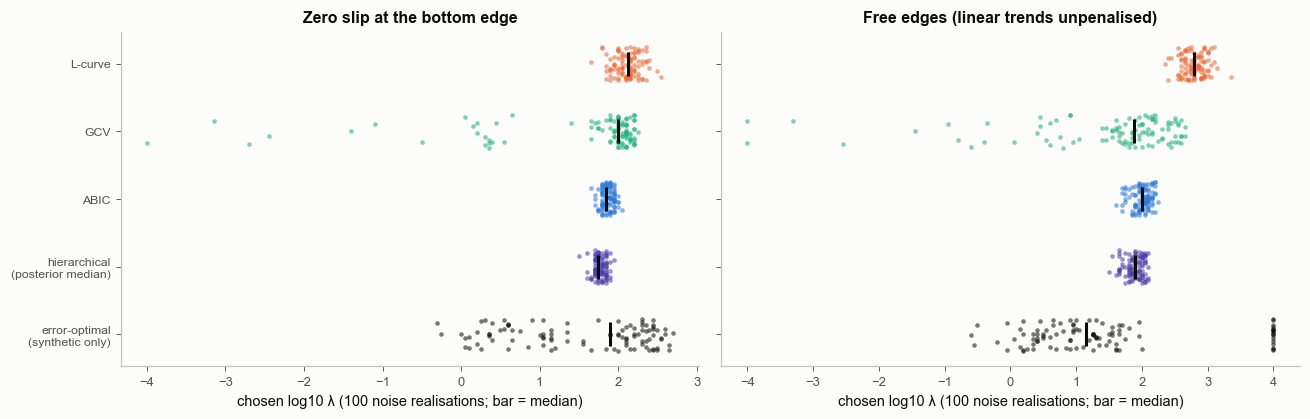

In [6]:
rep_free = {name: [] for name in pk0}
rep_free_err = {name: [] for name in pk0}
rng3 = np.random.default_rng(7)
for _ in range(REP):
    o = scan(G @ m_true + sig * rng3.standard_normal(xs.size), D_free)
    for name, i in picks(o).items():
        rep_free[name].append(np.log10(lams[i])); rep_free_err[name].append(o["err"][i])
print(f"over {REP} noise realisations (free edges):")
for name in pk0:
    print(f"{name:34s} median log10 λ {np.median(rep_free[name]):6.2f}   median rms error {np.median(rep_free_err[name]):.3f} m")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
names = list(pk0)
for ax, (rp, re_, title) in zip(axs, [(rep_picks, rep_err, "Zero slip at the bottom edge"),
                                      (rep_free, rep_free_err, "Free edges (linear trends unpenalised)")]):
    for j, name in enumerate(names):
        y = np.full(REP, j) + np.random.default_rng(j).uniform(-0.25, 0.25, REP)
        ax.scatter(rp[name], y, s=9, color=PCOL[name], alpha=0.55, lw=0)
        ax.plot(np.median(rp[name]), j, "|", color=S.INK, ms=16, mew=2)
    ax.set_yticks(range(len(names))); ax.set_yticklabels([n.replace(" (", "\n(") for n in names], fontsize=8)
    ax.set_xlabel("chosen log10 λ (100 noise realisations; bar = median)")
    ax.set_title(title)
axs[0].invert_yaxis()
fig.tight_layout()
bk.savefig(fig, "2-29_wrong_family")
plt.show()

**How to read it.** Each dot is the λ one method picked for one noise realisation. With the zero-slip edge (left)
the four data-based methods scatter around the median of the error-optimal λ. With free edges (right) GCV, ABIC
and the hierarchical posterior still agree with each other (the L-curve corner moves further), but now all four sit
well above the error-optimal λ and give larger slip errors (printed above). The dots piled at the edges of the
axis are noise draws whose criterion kept improving up to the smallest or largest λ tried (GCV on the left; the
error itself, with free edges, on the right).

The criteria answer "which λ suits these data *within this prior family*". None of them can tell that the family
itself (here: "linear trends in depth are free") does not suit a buried slip patch.

**Common misreadings.**
* "The criteria agree, so λ is right." Agreement says the data are consistent with the family, not that the family
  is right. Look at prior draws (2.09, notebook 2.12) before trusting any of them.

## 4. AIC and BIC: comparing models with different numbers of parameters

**In plain words.** A model with more parameters always fits at least as well, even if the extra parameters only
fit noise. An information criterion asks whether the improvement is bigger than what extra parameters buy by chance.
AIC charges 2 per parameter; BIC charges $\ln N_d$ per parameter, which for hundreds of data is a lot more.

**Precisely.** With $\hat L$ the maximum likelihood and $k$ free parameters,

$$\mathrm{AIC} = -2\ln\hat L + 2k,\qquad \mathrm{BIC} = -2\ln\hat L + k\ln N_d .$$

AIC (Akaike 1974) estimates how well the fitted model would predict *new* data of the same kind: its expected
predictive log density (the average log probability the fitted model gives to fresh data), which is a KL divergence up
to a constant (2.28). BIC (Schwarz 1978) approximates $-2\ln p(\mathbf d\mid\text{model})$, the log evidence (the
marginal likelihood of a whole model, reminder: 2.20 and 2.21), for large $N_d$ with a prior worth about one datum. ABIC is AIC applied
to the hyperparameters after the slip has been integrated out. Lower is better for all three; only differences
matter.

Test: one GPS component recorded daily for two years after an earthquake, σ = 2 mm, true signal
$u(t) = 8\log(1 + t/5\,\text{d}) + 4\,(1 - e^{-t/120\,\text{d}})$ mm (time constants known, amplitudes not).
Candidate models: log only, exponential only, log + exponential (the truth), log + exponential + linear trend (one
unnecessary parameter), and polynomials of degree 1 to 6.

In [7]:
t = np.arange(1, 731, 1.0)
TL, TE, SIGT = 5.0, 120.0, 2.0
truth_ts = 8.0 * np.log1p(t / TL) + 4.0 * (1 - np.exp(-t / TE))


def basis(name, tt):
    ts = tt / 730.0
    cols = {"log": [np.log1p(tt / TL)], "exp": [1 - np.exp(-tt / TE)],
            "log+exp": [np.log1p(tt / TL), 1 - np.exp(-tt / TE)],
            "log+exp+trend": [np.log1p(tt / TL), 1 - np.exp(-tt / TE), ts]}
    if name.startswith("poly"):
        return np.column_stack([ts ** j for j in range(int(name.split()[1]) + 1)])
    return np.column_stack([np.ones_like(tt)] + cols[name])


MODELS = ["log", "exp", "log+exp", "log+exp+trend"] + [f"poly {p}" for p in range(1, 7)]


def criteria_ts(d):
    rows = {}
    for nm in MODELS:
        A = basis(nm, t)
        coef = np.linalg.lstsq(A, d, rcond=None)[0]
        chi2 = np.sum((d - A @ coef) ** 2) / SIGT ** 2
        k = A.shape[1]
        m2ll = chi2 + t.size * np.log(2 * np.pi * SIGT ** 2)
        rows[nm] = dict(k=k, chi2=chi2, aic=m2ll + 2 * k, bic=m2ll + k * np.log(t.size), coef=coef)
    return rows


rng4 = np.random.default_rng(1)
d_ts = truth_ts + SIGT * rng4.standard_normal(t.size)
rows = criteria_ts(d_ts)
d_new = truth_ts + SIGT * rng4.standard_normal(t.size)          # a fresh realisation at the same days
amin, bmin = min(r_["aic"] for r_ in rows.values()), min(r_["bic"] for r_ in rows.values())
print(f"{'model':>14s} {'k':>2s} {'chi2':>8s} {'ΔAIC':>7s} {'ΔBIC':>7s} {'chi2 on fresh data':>19s} {'year-2 rms if fitted on year 1':>31s}")
for nm, r_ in rows.items():
    A = basis(nm, t)
    chi_new = np.sum((d_new - A @ r_["coef"]) ** 2) / SIGT ** 2
    first = t <= 365
    c1 = np.linalg.lstsq(A[first], d_ts[first], rcond=None)[0]
    extrap = np.sqrt(np.mean((A[~first] @ c1 - truth_ts[~first]) ** 2))
    print(f"{nm:>14s} {r_['k']:2d} {r_['chi2']:8.1f} {r_['aic'] - amin:7.1f} {r_['bic'] - bmin:7.1f} {chi_new:19.1f} {extrap:28.2f} mm")

         model  k     chi2    ΔAIC    ΔBIC  chi2 on fresh data  year-2 rms if fitted on year 1
           log  2    714.7     9.3     4.7               796.0                         0.18 mm
           exp  2   1101.2   395.8   391.2              1189.1                         3.23 mm
       log+exp  3    703.4     0.0     0.0               784.3                         0.43 mm
 log+exp+trend  4    702.9     1.5     6.1               784.7                         0.14 mm
        poly 1  2   3164.4  2459.0  2454.4              3335.6                        14.02 mm
        poly 2  3   1343.7   640.3   640.3              1524.9                        26.80 mm
        poly 3  4    956.2   254.7   259.3              1079.1                        71.82 mm
        poly 4  5    820.2   120.7   129.9               887.2                       167.83 mm
        poly 5  6    732.1    34.6    48.4               818.8                       546.51 mm
        poly 6  7    714.0    18.5    36.9        

models chosen over 500 noise realisations (truth: log+exp):
             log: AIC   36   BIC  231
         log+exp: AIC  386   BIC  265
   log+exp+trend: AIC   78   BIC    4
saved figures/2-29_aic_bic.png


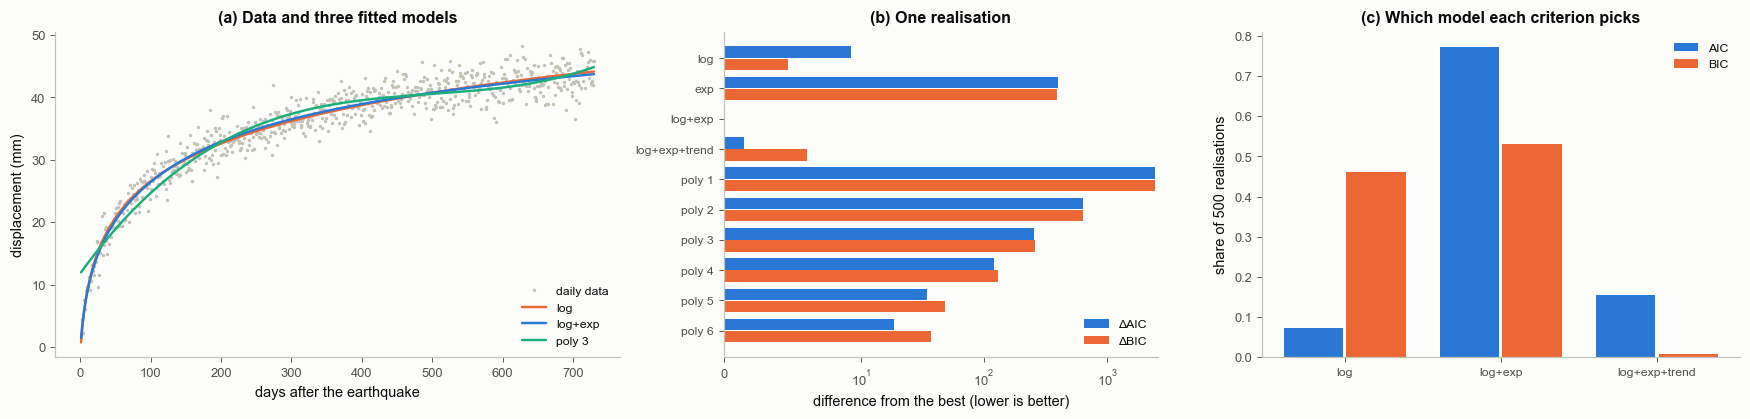

In [8]:
REP_TS = 500
rng5 = np.random.default_rng(3)
sel_a, sel_b = Counter(), Counter()
for _ in range(REP_TS):
    rr = criteria_ts(truth_ts + SIGT * rng5.standard_normal(t.size))
    sel_a[min(rr, key=lambda n: rr[n]["aic"])] += 1
    sel_b[min(rr, key=lambda n: rr[n]["bic"])] += 1
print(f"models chosen over {REP_TS} noise realisations (truth: log+exp):")
for nm in MODELS:
    if sel_a[nm] or sel_b[nm]:
        print(f"  {nm:>14s}: AIC {sel_a[nm]:4d}   BIC {sel_b[nm]:4d}")

fig, axs = plt.subplots(1, 3, figsize=(16, 3.9), gridspec_kw=dict(width_ratios=[1.3, 1, 1.1]))
ax = axs[0]
ax.plot(t, d_ts, ".", color="#c3c2b7", ms=2.5, label="daily data")
for nm, col in [("log", S.ORANGE), ("log+exp", S.BLUE), ("poly 3", S.AQUA)]:
    A = basis(nm, t)
    ax.plot(t, A @ rows[nm]["coef"], color=col, lw=1.6, label=nm)
ax.set_xlabel("days after the earthquake"); ax.set_ylabel("displacement (mm)")
ax.set_title("(a) Data and three fitted models"); ax.legend(fontsize=8, loc="lower right")
ax = axs[1]
yy = np.arange(len(MODELS))
ax.barh(yy - 0.2, [rows[n]["aic"] - amin for n in MODELS], height=0.38, color=S.BLUE, label="ΔAIC")
ax.barh(yy + 0.2, [rows[n]["bic"] - bmin for n in MODELS], height=0.38, color=S.ORANGE, label="ΔBIC")
ax.set_yticks(yy); ax.set_yticklabels(MODELS, fontsize=8); ax.invert_yaxis()
ax.set_xscale("symlog", linthresh=10); ax.set_xlabel("difference from the best (lower is better)")
ax.set_title("(b) One realisation"); ax.legend(fontsize=8, loc="lower right")
ax = axs[2]
keys = [n for n in MODELS if sel_a[n] or sel_b[n]]
xx = np.arange(len(keys))
ax.bar(xx - 0.2, [sel_a[n] / REP_TS for n in keys], width=0.38, color=S.BLUE, label="AIC")
ax.bar(xx + 0.2, [sel_b[n] / REP_TS for n in keys], width=0.38, color=S.ORANGE, label="BIC")
ax.set_xticks(xx); ax.set_xticklabels(keys, fontsize=8)
ax.set_ylabel(f"share of {REP_TS} realisations")
ax.set_title("(c) Which model each criterion picks"); ax.legend(fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-29_aic_bic")
plt.show()

**How to read it.** The table (printed above) is the worked example: χ² always drops as parameters are added, the
criteria add their penalties, and the column "χ² on fresh data" shows what AIC is trying to estimate: how well
each fitted model predicts a new realisation at the same days. The last column is a different question,
extrapolation: polynomials that fit year 1 can be far off in year 2. Panel (c) shows both failure directions.
AIC sometimes picks the model with the unnecessary trend; BIC, with its heavier penalty, often drops the weak
exponential term and picks log only (counts printed above). Neither criterion is "right"; they answer different
questions (prediction vs which model generated the data) and err on opposite sides.

**Common misreadings.**
* "The model with the lowest AIC is the true one." AIC ranks predictive ability; it may prefer a slightly
  over-complete model, and differences of a few units are within noise.
* "BIC is always safer." With weak effects and finite data it under-fits (panel c).

## 5. Caution 1: the evidence depends on how wide you made the prior

**In plain words.** The evidence (marginal likelihood) asks how well a model predicted the data *before* the fit,
averaged over its prior. Give a parameter a wider prior and the model spreads its predictions over more possible
data sets, so the actual data get less probability. Make the prior wide enough and the evidence prefers the
simpler model even when the complex one is true. AIC and BIC contain no prior, so they do not move.

**Precisely.** For a linear model with Gaussian priors $N(0, w^2)$ on the amplitudes, $\mathbf d\sim N(\mathbf 0,\ w^2\mathbf A\mathbf A^\top + \sigma^2\mathbf I)$
and $\ln Z$ is closed form. For $w$ much wider than the posterior width, each parameter costs roughly $\ln(w/\sigma_\text{post})$
(the Occam penalty), so the difference between models of different size changes with $\ln w$ without limit.

saved figures/2-29_evidence_prior_width.png


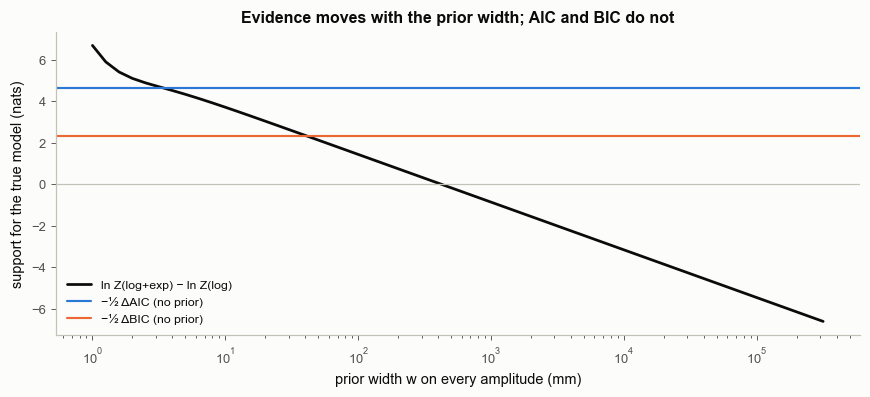

evidence difference: +6.70 nats at w = 1 mm, -6.62 at w = 3.2e+05 mm; it changes sign near w = 398 mm
for comparison, -1/2 dAIC = +4.64, -1/2 dBIC = +2.34 (independent of w)


In [9]:
def log_evidence(A, d, w, s=SIGT):
    """ln Z for d = A c + e, c ~ N(0, w^2 I), e ~ N(0, s^2 I), via the matrix determinant lemma (A is tall)."""
    k = A.shape[1]
    M_ = np.eye(k) / w ** 2 + A.T @ A / s ** 2
    b = A.T @ d / s ** 2
    quad = d @ d / s ** 2 - b @ np.linalg.solve(M_, b)
    logdet = 2 * len(d) * np.log(s) + 2 * k * np.log(w) + np.linalg.slogdet(M_)[1]
    return -0.5 * (quad + logdet + len(d) * np.log(2 * np.pi))


ws = np.logspace(0, 5.5, 56)
A_big, A_small = basis("log+exp", t), basis("log", t)
dz = np.array([log_evidence(A_big, d_ts, w) - log_evidence(A_small, d_ts, w) for w in ws])
half_daic = -0.5 * (rows["log+exp"]["aic"] - rows["log"]["aic"])
half_dbic = -0.5 * (rows["log+exp"]["bic"] - rows["log"]["bic"])
fig, ax = plt.subplots(figsize=(8, 3.7))
ax.semilogx(ws, dz, color=S.INK, lw=1.8, label="ln Z(log+exp) − ln Z(log)")
ax.axhline(half_daic, color=S.BLUE, lw=1.4, label="−½ ΔAIC (no prior)")
ax.axhline(half_dbic, color=S.ORANGE, lw=1.4, label="−½ ΔBIC (no prior)")
ax.axhline(0, color=S.AXIS, lw=0.8)
ax.set_xlabel("prior width w on every amplitude (mm)"); ax.set_ylabel("support for the true model (nats)")
ax.set_title("Evidence moves with the prior width; AIC and BIC do not")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
bk.savefig(fig, "2-29_evidence_prior_width")
plt.show()
cross = ws[np.argmin(np.abs(dz))]
print(f"evidence difference: {dz[0]:+.2f} nats at w = {ws[0]:.2g} mm, {dz[-1]:+.2f} at w = {ws[-1]:.2g} mm; "
      f"it changes sign near w = {cross:.3g} mm")
print(f"for comparison, -1/2 dAIC = {half_daic:+.2f}, -1/2 dBIC = {half_dbic:+.2f} (independent of w)")

**How to read it.** Above zero the true model is preferred. The evidence's verdict changes sign as the prior on the
amplitudes widens from millimetres to tens of metres (crossing printed above), although the data are identical.
A prior width is a modelling choice, so an evidence comparison is only as meaningful as that choice. (At the
narrowest widths both models are penalised for a prior that excludes the true amplitudes; the difference there
is large for that reason, not because the data became more decisive.)

**In practice.** Because ln Z moves with prior widths that are often set by convenience, report the fit with
prior-free numbers as well: WRMS and χ² of the posterior-mean prediction for each data set (section 7). Quote an
evidence difference only together with the prior widths it assumed.

## 6. Caution 2: never rank a weighting hyperparameter with the weighted misfit itself

**In plain words.** Suppose a balancing exponent β decides how much a small data set counts against a large one,
and each β gets its own fit. If you then rank the β values by the same weighted misfit that each fit minimised,
you are not comparing fits: you are comparing different rulers. The score changes with β simply because the
weights inside it change, and it drifts to whichever extreme makes the weighted numbers smallest.

**Precisely.** Two data sets: A, 200 daily GPS values whose noise is strongly correlated in time (an AR(1), or
first-order autoregressive, process: each day's error is 0.95 times the previous day's plus fresh noise; correlated
noise, 2.14) but treated as independent with σ_A = 1 mm, as is common; B, 10 independent
values with σ_B = 2 mm. Weights $w_k = (N_\text{total}/N_k)^{\beta}$ (β = 0: every datum counts the same; larger β: the
small data set counts more). The fit for each β minimises $\sum_k w_k\chi^2_k(\mathbf m)$. Four ways to score β:
* the trap: the same weighted misfit $\sum_k w_k\chi^2_k$ at its own optimum;
* β-free χ² of the same data, $\sum_k \chi^2_k$ with the fixed σ_k;
* β-free χ² of *held-out* data (a fresh realisation of both data sets);
* the error of the estimate (only a synthetic test can compute it).

share of the 300 repeats in which the reused weighted misfit rises at every step in beta: 1.00
weighted misfit reused as the score (the trap)  : best beta of the average curve 0.00; per repeat median 0.00 (5-95 % 0.00-0.00)
β-free χ², same data                            : best beta of the average curve 0.00; per repeat median 0.00 (5-95 % 0.00-0.00)
β-free χ², held-out data                        : best beta of the average curve 0.75; per repeat median 0.66 (5-95 % 0.00-2.50)
error of the estimate (synthetic only)          : best beta of the average curve 1.00; per repeat median 1.01 (5-95 % 0.00-2.50)
saved figures/2-29_circularity.png


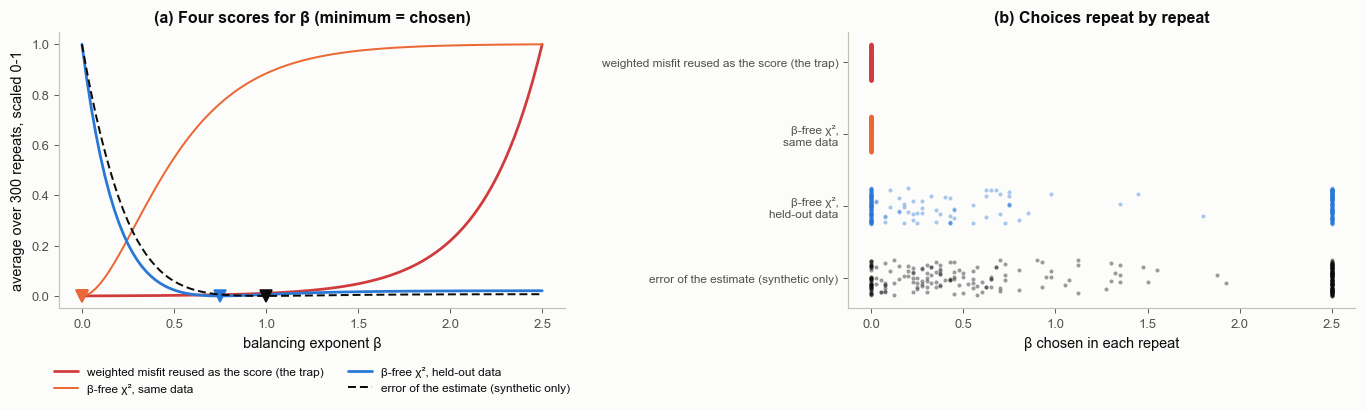

In [10]:
NA, NB, SA, SB, RHO = 200, 10, 1.0, 2.0, 0.95
tA = np.linspace(0, 1, NA)
GA = np.column_stack([np.ones(NA), 0.5 + 0.3 * tA])        # A sees mostly m1 + 0.5 m2
GB = np.column_stack([np.ones(NB), -np.ones(NB)])          # B sees m1 - m2
m2_true = np.array([1.0, 0.5])
betas = np.linspace(0, 2.5, 101)
NT = NA + NB


def noise_A(rng_):
    e = lfilter([np.sqrt(1 - RHO ** 2)], [1, -RHO], rng_.standard_normal(NA + 200))[200:]   # stationary AR(1), sd 1
    return SA * e


def beta_scores(rng_):
    dA, dB = GA @ m2_true + noise_A(rng_), GB @ m2_true + SB * rng_.standard_normal(NB)
    vA, vB = GA @ m2_true + noise_A(rng_), GB @ m2_true + SB * rng_.standard_normal(NB)     # held out
    out = {k: [] for k in ["trap", "chi2_in", "chi2_out", "err"]}
    for b in betas:
        wA, wB = (NT / NA) ** b, (NT / NB) ** b
        A = wA * GA.T @ GA / SA ** 2 + wB * GB.T @ GB / SB ** 2
        m = np.linalg.solve(A, wA * GA.T @ dA / SA ** 2 + wB * GB.T @ dB / SB ** 2)
        cA, cB = np.sum((dA - GA @ m) ** 2) / SA ** 2, np.sum((dB - GB @ m) ** 2) / SB ** 2
        out["trap"].append(wA * cA + wB * cB)
        out["chi2_in"].append(cA + cB)
        out["chi2_out"].append(np.sum((vA - GA @ m) ** 2) / SA ** 2 + np.sum((vB - GB @ m) ** 2) / SB ** 2)
        out["err"].append(np.linalg.norm(m - m2_true))
    return {k: np.array(v) for k, v in out.items()}


rng6 = np.random.default_rng(3)
runs = [beta_scores(rng6) for _ in range(300)]
SC = {"trap": ("weighted misfit reused as the score (the trap)", S.BAD),
      "chi2_in": ("β-free χ², same data", S.ORANGE),
      "chi2_out": ("β-free χ², held-out data", S.BLUE),
      "err": ("error of the estimate (synthetic only)", S.INK)}
mono = np.mean([np.all(np.diff(r_["trap"]) > 0) for r_ in runs])
print(f"share of the 300 repeats in which the reused weighted misfit rises at every step in beta: {mono:.2f}")
for k, (lab, _) in SC.items():
    mean_curve = np.mean([r_[k] for r_ in runs], axis=0)
    per = [betas[np.argmin(r_[k])] for r_ in runs]
    print(f"{lab:48s}: best beta of the average curve {betas[np.argmin(mean_curve)]:.2f}; "
          f"per repeat median {np.median(per):.2f} (5-95 % {np.percentile(per, 5):.2f}-{np.percentile(per, 95):.2f})")

fig, axs = plt.subplots(1, 2, figsize=(12.5, 3.9))
ax = axs[0]
for k, (lab, col) in SC.items():
    mc = np.mean([r_[k] for r_ in runs], axis=0)
    mc = (mc - mc.min()) / (mc.max() - mc.min())
    ax.plot(betas, mc, color=col, lw=1.8 if k in ("trap", "chi2_out") else 1.3,
            ls=(0, (4, 2)) if k == "err" else "-", label=lab)
    ax.plot(betas[np.argmin(mc)], 0, "v", color=col, ms=8)
ax.set_xlabel("balancing exponent β"); ax.set_ylabel("average over 300 repeats, scaled 0-1")
ax.set_title("(a) Four scores for β (minimum = chosen)")
ax.legend(fontsize=7.8, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
ax = axs[1]
for j, k in enumerate(SC):
    per = [betas[np.argmin(r_[k])] for r_ in runs]
    y = np.full(len(per), j) + np.random.default_rng(j).uniform(-0.25, 0.25, len(per))
    ax.scatter(per, y, s=7, color=SC[k][1], alpha=0.4, lw=0)
ax.set_yticks(range(4)); ax.set_yticklabels([SC[k][0].replace(", ", ",\n") for k in SC], fontsize=7.8)
ax.invert_yaxis(); ax.set_xlabel("β chosen in each repeat")
ax.set_title("(b) Choices repeat by repeat")
fig.tight_layout()
bk.savefig(fig, "2-29_circularity")
plt.show()

**How to read it.** (a) The reused weighted misfit (red) rises steadily with β in every repeat (share printed
above), so it always chooses β = 0, "the large data set dominates", for a reason that has nothing to do with fit
quality: larger β makes the small data set's weight, and with it the score, bigger. The β-free χ² of the same data
also chooses β = 0, for a different reason: an exact weighted least-squares fit at β = 0 *is* the minimum of the
unweighted χ², so in-sample χ² cannot discriminate here. The β-free χ² of held-out data has its minimum in the
interior, in the same range as the β with the smallest true error (both printed above). (b) Repeat by repeat, a single held-out set is noisy: use
many folds (cross-validation) before trusting one number.

**In practice.** The trap appears whenever a knob changes the weights inside the score used to rank it: balancing
exponents between data sets, per-data-set weights, a smoothing weight scored by the regularised objective, or an
emulator of a "log-evidence" proxy that contains the knob. Score with a quantity that does not contain the knob, such
as β-free χ² per data set, preferably on held-out data or by cross-validation. When the fit is not an exact weighted
least-squares minimiser (for example a posterior mean pulled by a prior), in-sample β-free χ² is not automatically
flat, but held-out data remain the safe default.

## 7. Reporting the fit: WRMS and χ² per data set, and always the plot

**In plain words.** One total misfit number hides which data set is badly fitted, and a noise level set too loose
makes any fit look excellent. Report each data set separately, and look at the residuals.

**Precisely.** For data set $k$ with $N_k$ values and assumed σ_i: $\chi^2_k = \sum_i (r_i/\sigma_i)^2$ and
$\mathrm{WRMS}_k = \sqrt{\chi^2_k/N_k}$. $\mathrm{WRMS}_k \approx 1$ means residuals at the assumed noise level; much smaller means the
assumed σ is too loose (or the model overfits); much larger means misfit beyond the noise.

wrong model (exp only), assumed sigma  2.0 mm: WRMS = 1.23
wrong model (exp only), assumed sigma 10.0 mm: WRMS = 0.25
correlation of neighbouring residuals: 0.35 (independent noise would give about 0)
saved figures/2-29_reporting.png


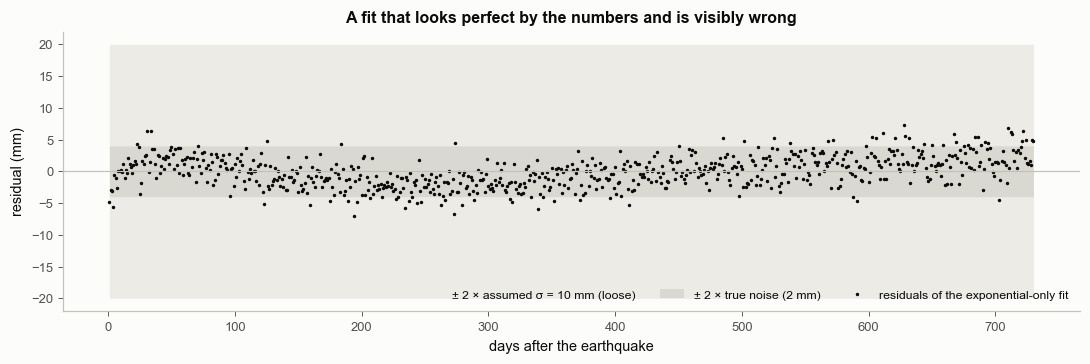

In [11]:
A_exp = basis("exp", t)
c_exp = np.linalg.lstsq(A_exp, d_ts, rcond=None)[0]
resid = d_ts - A_exp @ c_exp
for s_assumed in [2.0, 10.0]:
    print(f"wrong model (exp only), assumed sigma {s_assumed:4.1f} mm: WRMS = {np.sqrt(np.mean((resid / s_assumed) ** 2)):.2f}")
lag1 = np.corrcoef(resid[:-1], resid[1:])[0, 1]
print(f"correlation of neighbouring residuals: {lag1:.2f} (independent noise would give about 0)")
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.fill_between(t, -2 * 10.0, 2 * 10.0, color="#ecebe6", lw=0, label="± 2 × assumed σ = 10 mm (loose)")
ax.fill_between(t, -2 * SIGT, 2 * SIGT, color="#d9d8d1", lw=0, label="± 2 × true noise (2 mm)")
ax.plot(t, resid, ".", ms=2.5, color=S.INK, label="residuals of the exponential-only fit")
ax.axhline(0, color=S.AXIS, lw=0.8)
ax.set_xlabel("days after the earthquake"); ax.set_ylabel("residual (mm)")
ax.set_title("A fit that looks perfect by the numbers and is visibly wrong")
ax.legend(fontsize=8, loc="lower right", ncol=3)
fig.tight_layout()
bk.savefig(fig, "2-29_reporting")
plt.show()

**How to read it.** With the loose σ, the wrong model's WRMS is far below 1 (printed above): by the numbers it fits
"better than the noise"; with the true σ it is above 1. The residuals tell the truth: a systematic curve in the
first months and clearly correlated neighbours (printed above), which independent noise does not produce.

**Common misreadings.**
* "χ²/N ≪ 1 is a great fit." It is a warning that σ is too loose or the model overfits.
* "Total χ² is fine, so every data set is fine." A large data set can hide a badly fitted small one; report each.

## 8. Summary

| tool | what it picks | needs | watch out for |
|---|---|---|---|
| L-curve | the corner between misfit and roughness | nothing but the fits | corner can be vague; no uncertainty |
| GCV | best average prediction of left-out data | the hat matrix | assumes independent errors |
| ABIC | λ that made the data most probable (peak of the marginal likelihood) | linear-Gaussian closed form (or an estimate) | rank-deficient priors need the rank term; inherits the prior family |
| hierarchical posterior | all λ, weighted by their marginal likelihood × prior | sampling or a grid | prior on λ; same family caveat |
| AIC | best predictor of new data | maximum likelihood, k | may keep an unnecessary parameter |
| BIC | approximately the most probable model | maximum likelihood, k, N_d | under-fits weak effects |
| evidence | most probable model under *your* priors | priors on every parameter | changes with prior width |

Next: [**2.30 · Hierarchical Bayes: who sets the weights?**](2-30_hierarchical_bayes_weights.ipynb).